Benchmark: shell obstacle course
===

Date: 22 of October 2026

Author: Saullo G. P. Castro

Belytschko et al. [1] assembled three linear problems, the "obstacle course" of their Section 5, that together test whether a shell element represents inextensional bending, rigid-body rotations about the normal and complex membrane states: the Scordelis-Lo roof, the pinched cylinder with rigid diaphragms and the pinched hemispherical shell. This notebook runs the three problems with the four shell elements of `pyfe3d`, `Quad4`, `Quad4R`, `Tria3R` and `Tria3DSG`, each with its default attributes, on $N \times N$ meshes of the symmetric part of each shell, and compares the converged and the coarse-mesh results with the reference values of Table 3 of [1] (p. 239). The roof and the hemisphere are also problems of MacNeal and Harder [2], whose Tables 13 and 14 give the results of the QUAD4 of MSC/NASTRAN, compared at the end.

| | Scordelis-Lo roof | Pinched cylinder | Hemispherical shell |
|---|---|---|---|
| Length $L$ | 50.0 | 600.0 | - |
| Radius $R$ | 25.0 | 300.0 | 10.0 |
| Thickness $t$ | 0.25 | 3.0 | 0.04 |
| $E$ | $4.32 \times 10^8$ | $3.0 \times 10^6$ | $6.825 \times 10^7$ |
| $\nu$ | 0.0 | 0.3 | 0.3 |
| Load | gravity, 90.0 per unit area | two opposite radial forces $F = 1.0$ | radial forces $F = \pm 2.0$ alternating at 90 degrees |
| Reference | vertical displacement at the midside of the free edge, 0.3024 | radial displacement under the load, $0.18248 \times 10^{-4}$ | radial displacement under the load, 0.0924 |

The table is Table 3 of [1]. The modelling choices that [1] does not state are given with each problem. The triangular meshes are obtained by cutting every quadrilateral along its diagonal 1-3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve

from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d import (Quad4, Quad4Data, Quad4Probe, Quad4R, Quad4RData,
                    Quad4RProbe, Tria3R, Tria3RData, Tria3RProbe, Tria3DSG,
                    Tria3DSGData, Tria3DSGProbe, INT, DOUBLE, DOF)

ELEMENTS = {
    'Quad4': (Quad4, Quad4Data, Quad4Probe),
    'Quad4R': (Quad4R, Quad4RData, Quad4RProbe),
    'Tria3R': (Tria3R, Tria3RData, Tria3RProbe),
    'Tria3DSG': (Tria3DSG, Tria3DSGData, Tria3DSGProbe),
}


def split(quads):
    # two triangles per quadrilateral, cut along the diagonal 1-3
    return [t for (n1, n2, n3, n4) in quads for t in ((n1, n2, n3), (n1, n3, n4))]


def stiffness(ncoords, quads, name, prop):
    Elem, Data, Probe = ELEMENTS[name]
    conn = split(quads) if name.startswith('Tria') else quads
    data, probe = Data(), Probe()
    ncf = np.ascontiguousarray(ncoords, dtype=DOUBLE).flatten()
    N = DOF*ncoords.shape[0]
    size = data.KC0_SPARSE_SIZE*len(conn)
    KC0r = np.zeros(size, dtype=INT)
    KC0c = np.zeros(size, dtype=INT)
    KC0v = np.zeros(size, dtype=DOUBLE)
    areas = np.zeros(len(conn))
    for k, nodes in enumerate(conn):
        e = Elem(probe)
        for i, n in enumerate(nodes):
            setattr(e, 'n%d' % (i + 1), n)
            setattr(e, 'c%d' % (i + 1), DOF*n)
        e.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        e.update_rotation_matrix(ncf)
        e.update_probe_xe(ncf)
        e.update_area()
        e.update_KC0(KC0r, KC0c, KC0v, prop)
        areas[k] = e.area
    K = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()
    return K, conn, areas


def solve(K, bk, f):
    u = np.zeros(K.shape[0])
    bu = ~bk
    u[bu] = spsolve(K[bu][:, bu], f[bu])
    return u


def area_load(ncoords, conn, areas, q):
    # nodal forces of a load per unit area q, lumped equally to the nodes
    f = np.zeros(DOF*ncoords.shape[0])
    for nodes, A in zip(conn, areas):
        for n in nodes:
            f[DOF*n:DOF*n + 3] += np.asarray(q)*A/len(nodes)
    return f


def mapped_grid(n, X, Y, Z):
    # an n by n grid of quadrilaterals on the surface given by the
    # (n + 1, n + 1) arrays of coordinates X, Y and Z
    ids = np.arange((n + 1)**2).reshape(n + 1, n + 1)
    quads = [(ids[i, j], ids[i + 1, j], ids[i + 1, j + 1], ids[i, j + 1])
             for i in range(n) for j in range(n)]
    return np.column_stack((X.ravel(), Y.ravel(), Z.ravel())), ids, quads


def fix(bk, mask, dofs):
    for d in dofs:
        bk[d::DOF] |= mask


def grade(normalised):
    # letter grade of MacNeal and Harder [2], p. 14
    err = 100*abs(normalised - 1.)
    for letter, limit in (('A', 2.), ('B', 10.), ('C', 20.), ('D', 50.)):
        if err <= limit:
            return letter
    return 'F'


NS = (2, 4, 6, 8, 10, 12, 16, 24, 32, 48)

Scordelis-Lo roof
---

A cylindrical roof of radius 25.0 and length 50.0, with its axis along $y$, $z$ vertical and a half-angle of 40 degrees, supported at both ends by rigid diaphragms and loaded by its own weight, 90.0 per unit area in the $-z$ direction (Fig. 5 and Table 3 of [1]). One quarter is modelled, $0 \le \theta \le 40^\circ$ from the crown and $0 \le y \le 25$ from the diaphragm, with symmetry at the crown, $u_x = r_y = r_z = 0$, and at mid-length, $u_y = r_x = r_z = 0$. [1] does not define the diaphragm for this problem; it is taken from Fig. 8 of [2], $u_x = u_z = 0$ on the curved edge. The gravity load is lumped to the nodes. The result is the vertical displacement at the midside of the free edge.

In [2]:
def scordelis_lo(name, n):
    R, L = 25., 50.
    T, Y = np.meshgrid(np.linspace(0., np.deg2rad(40.), n + 1),
                       np.linspace(0., L/2, n + 1), indexing='ij')
    ncoords, ids, quads = mapped_grid(n, R*np.sin(T), Y, R*np.cos(T))
    prop = isotropic_plate(thickness=0.25, E=4.32e8, nu=0.)
    K, conn, areas = stiffness(ncoords, quads, name, prop)
    x, y, z = ncoords.T
    bk = np.zeros(K.shape[0], dtype=bool)
    fix(bk, np.isclose(y, 0.), (0, 2))        # diaphragm
    fix(bk, np.isclose(y, L/2), (1, 3, 5))    # symmetry at mid-length
    fix(bk, np.isclose(x, 0.), (0, 4, 5))     # symmetry at the crown
    u = solve(K, bk, area_load(ncoords, conn, areas, (0., 0., -90.)))
    return -u[DOF*ids[n, n] + 2]

Pinched cylinder with rigid diaphragms
---

A cylinder of radius 300.0 and length 600.0, axis along $y$, pinched at mid-length by two diametrically opposite radial forces $F = 1.0$, and constrained at each end by a rigid diaphragm, defined in Table 3 of [1] as $u_x = u_y = \phi_z = 0$ with $z$ the axis of the cylinder in their Fig. 5, here $u_x = u_z = r_y = 0$. One eighth is modelled, $0 \le \theta \le 90^\circ$ from the loaded generator and $0 \le y \le 300$ from mid-length, with symmetry on the three cut planes: $u_x = r_y = r_z = 0$ at $x = 0$, $u_z = r_x = r_y = 0$ at $z = 0$ and $u_y = r_x = r_z = 0$ at mid-length. The load node carries $F/4$. The result is the radial displacement under the load.

In [3]:
def pinched_cylinder(name, n):
    R, L, F = 300., 600., 1.
    T, Y = np.meshgrid(np.linspace(0., np.pi/2, n + 1),
                       np.linspace(0., L/2, n + 1), indexing='ij')
    ncoords, ids, quads = mapped_grid(n, R*np.sin(T), Y, R*np.cos(T))
    prop = isotropic_plate(thickness=3., E=3.e6, nu=0.3)
    K, conn, areas = stiffness(ncoords, quads, name, prop)
    x, y, z = ncoords.T
    bk = np.zeros(K.shape[0], dtype=bool)
    fix(bk, np.isclose(y, L/2), (0, 2, 4))          # diaphragm
    fix(bk, np.isclose(y, 0.), (1, 3, 5))           # symmetry at mid-length
    fix(bk, np.isclose(x, 0.), (0, 4, 5))           # symmetry, plane x = 0
    fix(bk, np.isclose(z, 0., atol=1e-9), (2, 3, 4))  # symmetry, plane z = 0
    f = np.zeros(K.shape[0])
    load = ids[0, 0]
    f[DOF*load + 2] = -F/4
    u = solve(K, bk, f)
    return -u[DOF*load + 2]

Pinched hemispherical shell
---

A hemisphere of radius 10.0 with a free equator, loaded at the equator by four radial point loads alternating in sign at 90 degrees. Fig. 1(b) of [1], whose caption refers to their Table 3 for the data of the problem, and Fig. 9 of [2] give a hole at the pole, of 18 degrees, which is modelled here; the reference 0.0924 of [1] is, according to [2] (Table 5(b)), a lower bound computed for the hemisphere without the hole, and [2] normalises the results with the hole by 0.094 instead. One quadrant is modelled with symmetry on the planes $x = 0$, $u_x = r_y = r_z = 0$, and $y = 0$, $u_y = r_x = r_z = 0$. The quadrant carries $F = 1.0$ at each load point, outward along $x$ and inward along $y$, as drawn in Figs. 1(b) and 5 of [1], half of the $F = \pm 2.0$ of their Table 3 because each load point lies on a plane of symmetry. Fig. 9 of [2] labels the forces "F = 2.0 (on quadrant)"; with 2.0 applied to the quadrant every result below doubles. Nothing in the quadrant prevents a translation along $z$, so $u_z = 0$ is imposed at one node of the hole, which does not change the solution because the loads have no component along $z$. The result is the radial displacement under the load along $x$.

In [4]:
def hemisphere(name, n):
    R, F = 10., 1.
    PSI, PHI = np.meshgrid(np.linspace(np.pi/2, np.deg2rad(18.), n + 1),
                           np.linspace(0., np.pi/2, n + 1), indexing='ij')
    ncoords, ids, quads = mapped_grid(n, R*np.sin(PSI)*np.cos(PHI),
                                      R*np.sin(PSI)*np.sin(PHI), R*np.cos(PSI))
    prop = isotropic_plate(thickness=0.04, E=6.825e7, nu=0.3)
    K, conn, areas = stiffness(ncoords, quads, name, prop)
    x, y, z = ncoords.T
    bk = np.zeros(K.shape[0], dtype=bool)
    fix(bk, np.isclose(x, 0., atol=1e-9), (0, 4, 5))
    fix(bk, np.isclose(y, 0., atol=1e-9), (1, 3, 5))
    bk[DOF*ids[n, 0] + 2] = True
    f = np.zeros(K.shape[0])
    f[DOF*ids[0, 0] + 0] = +F
    f[DOF*ids[0, n] + 1] = -F
    u = solve(K, bk, f)
    return u[DOF*ids[0, 0] + 0]

Convergence
---

Every problem is solved with $N$ from 2 to 48 elements per side, on the quadrilateral mesh or on the triangles obtained from it, and the result is normalised by the reference of Table 3 of [1].

In [5]:
PROBLEMS = {'Scordelis-Lo roof': (scordelis_lo, 0.3024),
            'Pinched cylinder': (pinched_cylinder, 0.18248e-4),
            'Hemispherical shell': (hemisphere, 0.0924)}

res = {}
for problem, (func, ref) in PROBLEMS.items():
    print(problem + ', normalised displacement')
    print('%-4s' % 'N' + ''.join('%10s' % name for name in ELEMENTS))
    for n in NS:
        for name in ELEMENTS:
            res[problem, name, n] = func(name, n)/ref
        print('%-4d' % n + ''.join('%10.3f' % res[problem, name, n] for name in ELEMENTS))
    print()

Scordelis-Lo roof, normalised displacement
N        Quad4    Quad4R    Tria3R  Tria3DSG
2        1.416     1.176     0.896     0.665
4        1.059     0.944     0.926     0.675
6        1.022     0.961     0.964     0.783
8        1.010     0.973     0.975     0.853
10       1.006     0.980     0.982     0.895


12       1.003     0.985     0.985     0.922


16       1.001     0.989     0.989     0.951


24       1.000     0.993     0.993     0.975


32       0.999     0.994     0.994     0.984


...

12       0.903     0.917     0.664     0.803


16       0.975     0.976     0.862     0.926


24       1.005     1.002     0.974     0.985


32       1.011     1.008     0.998     0.998


48       1.013     1.011     1.008     1.006



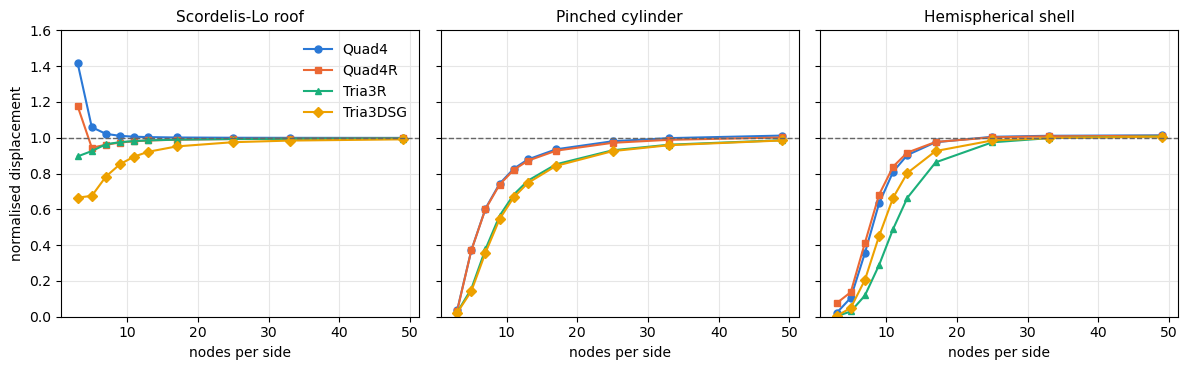

In [6]:
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
markers = ['o', 's', '^', 'D']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, problem in zip(axes, PROBLEMS):
    for name, c, m in zip(ELEMENTS, colors, markers):
        ax.plot(np.array(NS) + 1, [res[problem, name, n] for n in NS],
                color=c, marker=m, markersize=5, lw=1.5, label=name)
    ax.axhline(1., color='0.4', lw=1, ls='--')
    ax.set_title(problem, fontsize=11)
    ax.set_xlabel('nodes per side')
    ax.set_ylim(0., 1.6)
    ax.grid(color='0.9')
axes[0].set_ylabel('normalised displacement')
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

Checks
---

The convergence is checked on the finest mesh, $N = 48$, with the tolerance of grade A of [2], 2%. On the coarse meshes the grade of [2] is printed for the meshes it uses in its Table 16, $N = 4$ for the roof and $N = 8$ for the hemisphere, and for $N = 16$ (17 nodes per side) for the cylinder, the mesh on which [1] (p. 242) finds their 4-node element with selective reduced integration "still 5% in error".

In [7]:
COARSE = {'Scordelis-Lo roof': 4, 'Pinched cylinder': 16, 'Hemispherical shell': 8}
print('%-22s %-8s %12s %12s %10s %12s' % ('problem', 'element', 'N = 48', 'converged', 'coarse N',
                                          'grade [2]'))
for problem in PROBLEMS:
    for name in ELEMENTS:
        v = res[problem, name, 48]
        nc = COARSE[problem]
        print('%-22s %-8s %12.4f %12s %10d %12s'
              % (problem, name, v, 'PASS' if abs(v - 1.) <= 0.02 else 'FAIL', nc,
                 grade(res[problem, name, nc])))

problem                element        N = 48    converged   coarse N    grade [2]
Scordelis-Lo roof      Quad4          0.9991         PASS          4            B
Scordelis-Lo roof      Quad4R         0.9960         PASS          4            B
Scordelis-Lo roof      Tria3R         0.9955         PASS          4            B
Scordelis-Lo roof      Tria3DSG       0.9910         PASS          4            D
Pinched cylinder       Quad4          1.0120         PASS         16            B
Pinched cylinder       Quad4R         1.0014         PASS         16            B
Pinched cylinder       Tria3R         0.9862         PASS         16            C
Pinched cylinder       Tria3DSG       0.9848         PASS         16            C
Hemispherical shell    Quad4          1.0134         PASS          8            D
Hemispherical shell    Quad4R         1.0108         PASS          8            D
Hemispherical shell    Tria3R         1.0081         PASS          8            F
Hemispherical sh

Comparison with MacNeal and Harder
---

Tables 13 and 14 of [2] give the QUAD4 of MSC/NASTRAN on the roof and on the hemisphere, normalised by 0.3024 and 0.094 respectively. The results of `pyfe3d` are normalised in the same way below.

In [8]:
MH_QUAD4 = {'Scordelis-Lo roof': (0.3024, {2: 1.376, 4: 1.050, 6: 1.018, 8: 1.008, 10: 1.004}),   # Table 13 of [2]
            'Hemispherical shell': (0.094, {2: 0.972, 4: 1.024, 6: 1.013, 8: 1.005, 10: 1.001,
                                            12: 0.998})}                                          # Table 14 of [2]
for problem, (ref_mh, table) in MH_QUAD4.items():
    ref = PROBLEMS[problem][1]
    print(problem + ', displacement normalised by %g' % ref_mh)
    print('%-4s' % 'N' + ''.join('%10s' % name for name in ELEMENTS) + '  MH QUAD4')
    for n, v in table.items():
        print('%-4d' % n + ''.join('%10.3f' % (res[problem, name, n]*ref/ref_mh) for name in ELEMENTS)
              + '%10.3f' % v)
    print()

Scordelis-Lo roof, displacement normalised by 0.3024
N        Quad4    Quad4R    Tria3R  Tria3DSG  MH QUAD4
2        1.416     1.176     0.896     0.665     1.376
4        1.059     0.944     0.926     0.675     1.050
6        1.022     0.961     0.964     0.783     1.018
8        1.010     0.973     0.975     0.853     1.008
10       1.006     0.980     0.982     0.895     1.004

Hemispherical shell, displacement normalised by 0.094
N        Quad4    Quad4R    Tria3R  Tria3DSG  MH QUAD4
2        0.021     0.074     0.003     0.004     0.972
4        0.104     0.135     0.029     0.049     1.024
6        0.350     0.406     0.117     0.202     1.013
8        0.622     0.670     0.284     0.443     1.005
10       0.797     0.825     0.483     0.654     1.001
12       0.888     0.902     0.653     0.789     0.998



Discussion
---

The output above is the result of the default elements, with no parameter adjusted to these problems.

- **`Quad4`** is within 2% of the three references at $N = 48$. On the roof it behaves like the QUAD4 of [2] on every mesh, over-flexible on the coarsest. On the pinched cylinder it converges from below, with an error of 6.5% at 17 nodes per side, close to the 5% that [1] (p. 242) reports for their 4-node element with selective reduced integration on that mesh, and ends 1.2% above the reference. The hemisphere is where it differs most from the QUAD4 of [2]: far too stiff on the coarse meshes, 10% of the displacement at $N = 4$ against 102% for the QUAD4, and within 3% of the reference of [1] only from $N = 16$.
- **`Quad4R`** is within 1.1% of the three references at $N = 48$ and grade B on the coarse meshes of the roof and the cylinder, converging from below, and overshooting by 1.1% on the hemisphere, where it is the most flexible element on the coarse meshes. Since version 0.12.0 its bending and transverse shear have the physical stabilisation of Belytschko and Leviathan (1994), see the Notes of `pyfe3d.quad4r`; up to version 0.11, with Brockman's hourglass stiffnesses, it converged more slowly and was still 3% and 6% too stiff on the roof and on the cylinder at $N = 48$.
- **`Tria3R`** is within 2% of the three references at $N = 48$. Since version 0.12.0 it takes by default the transverse shear field of `Tria3DSG`, and the drilling enrichment of its membrane makes it the more accurate triangle on the roof, within 4% from $N = 6$ where `Tria3DSG` needs $N = 24$, and slightly better on the cylinder. On the coarse meshes of the hemisphere it is stiffer than `Tria3DSG`, 0.288 against 0.451 at $N = 8$, because on a doubly curved surface the drilling rotations of the Allman field pick up the bending rotations of the neighbouring facets; the two agree from $N = 32$. This is why `Tria3R` is the recommended triangle of `pyfe3d`, and `Tria3DSG` the better choice on coarse meshes of doubly curved shells. With the centroid-sampled transverse shear of the versions up to 0.11 (`shear_model = 0` with `alpha_shear_locking = 0.7`) it did not converge within $N = 48$: it settled 12% below the reference on the roof and 18% below on the hemisphere, see the Notes of `pyfe3d.tria3r`.
- **`Tria3DSG`** is within 2% of the three references at $N = 48$, converging from below and more slowly than `Quad4` on the coarse meshes, with no parameter to set.

References
---

[1] Belytschko, T., Stolarski, H., Liu, W. K., Carpenter, N., and Ong, J. S.-J., Stress projection for membrane and shear locking in shell finite elements, Computer Methods in Applied Mechanics and Engineering, 51(1-3), 221-258, 1985. https://doi.org/10.1016/0045-7825(85)90035-0

[2] MacNeal, R. H., and Harder, R. L., A proposed standard set of problems to test finite element accuracy, Finite Elements in Analysis and Design, 1(1), 3-20, 1985. https://doi.org/10.1016/0168-874X(85)90003-4